# 04 model training

Notebook khởi tạo cho dự án UAV-FD.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score, 
    recall_score, 
    f1_score, 
    accuracy_score, 
    confusion_matrix
)

# 1. Đọc dữ liệu đã gộp từ thư mục data/processed
df_uav = pd.read_csv("../data/processed/imu_combined.csv")

# 2. Đảm bảo cột Label là số nguyên (0: Normal, 1: Fault)
df_uav['Label'] = pd.to_numeric(df_uav['Label']).astype(int)

# 3. Khai báo 6 biến đầu vào (Input features), biến mục tiêu (Target) và cột nhóm chuyến bay
features = ['AccX', 'AccY', 'AccZ', 'GyrX', 'GyrY', 'GyrZ']
target = 'Label'
group_col = 'source_file'

X = df_uav[features].values
y = df_uav[target].values
groups = df_uav[group_col].values

print(f"Tổng số dòng dữ liệu: {len(df_uav):,}")
print(f"Tổng số chuyến bay (files): {df_uav[group_col].nunique()}")
print("Số dòng theo từng trạng thái (0 = Normal, 1 = Fault):")
print(df_uav[target].value_counts())

Tổng số dòng dữ liệu: 767,763
Tổng số chuyến bay (files): 18
Số dòng theo từng trạng thái (0 = Normal, 1 = Fault):
Label
1    531643
0    236120
Name: count, dtype: int64


In [2]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

fold_info = []
for fold_idx, (train_idx, test_idx) in enumerate(sgkf.split(X, y, groups=groups), start=1):
    train_files = np.unique(groups[train_idx])
    test_files = np.unique(groups[test_idx])
    
    # Kiểm tra xem có file nào bị trùng giữa Train và Test không (Data Leakage check)
    overlap = set(train_files).intersection(set(test_files))
    
    fold_info.append({
        'Fold': fold_idx,
        'Số mẫu Train': len(train_idx),
        'Số mẫu Test': len(test_idx),
        'Số file Train': len(train_files),
        'Số file Test': len(test_files),
        'Danh sách file Test': ", ".join(test_files),
        'Trùng file (Leakage)': len(overlap)
    })

df_folds = pd.DataFrame(fold_info)
print("=== BẢNG PHÂN CHIA 5-FOLD THEO CHUYẾN BAY (CHỐNG DATA LEAKAGE) ===")
display(df_folds)

=== BẢNG PHÂN CHIA 5-FOLD THEO CHUYẾN BAY (CHỐNG DATA LEAKAGE) ===


,Fold,Số mẫu Train,Số mẫu Test,Số file Train,Số file Test,Danh sách file Test,Trùng file (Leakage)
0,1,632051,135712,15,3,"FAULT_M1_5.mat, FAULT_M6_5.mat, NO_FAULT4.mat",0
1,2,592196,175567,14,4,"FAULT_M1_10.mat, FAULT_M4_5.mat, FAULT_M5_10.m...",0
2,3,613737,154026,14,4,"FAULT_M2_10.mat, FAULT_M2_5.mat, NO_FAULT1.mat...",0
3,4,630499,137264,15,3,"FAULT_M3_5.mat, FAULT_M4_10.mat, NO_FAULT6.mat",0
4,5,602569,165194,14,4,"FAULT_M3_10.mat, FAULT_M5_5.mat, FAULT_M6_10.m...",0


In [3]:
# 1. Khởi tạo mô hình với random_state=42 cố định để đảm bảo Reproducibility
lr_model = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(random_state=42, max_iter=1000))
])

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

lr_records = []
rf_records = []

cm_lr_total = np.zeros((2, 2), dtype=int)
cm_rf_total = np.zeros((2, 2), dtype=int)

# Lưu lại dự đoán của toàn bộ các fold để làm Error Analysis ở bước sau
all_test_indices = []
all_preds_lr = []
all_preds_rf = []

print("Đang huấn luyện 5 folds, vui lòng đợi trong giây lát...")

for fold_idx, (train_idx, test_idx) in enumerate(sgkf.split(X, y, groups=groups), start=1):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    
    # --- Mô hình 1: Logistic Regression ---
    lr_model.fit(X_train, y_train)
    y_pred_lr = lr_model.predict(X_test)
    
    lr_records.append({
        'Fold': fold_idx,
        'Precision': precision_score(y_test, y_pred_lr, pos_label=1, zero_division=0),
        'Recall': recall_score(y_test, y_pred_lr, pos_label=1, zero_division=0),
        'F1-score': f1_score(y_test, y_pred_lr, pos_label=1, zero_division=0),
        'Accuracy': accuracy_score(y_test, y_pred_lr)
    })
    cm_lr_total += confusion_matrix(y_test, y_pred_lr, labels=[0, 1])
    
    # --- Mô hình 2: Random Forest ---
    rf_model.fit(X_train, y_train)
    y_pred_rf = rf_model.predict(X_test)
    
    rf_records.append({
        'Fold': fold_idx,
        'Precision': precision_score(y_test, y_pred_rf, pos_label=1, zero_division=0),
        'Recall': recall_score(y_test, y_pred_rf, pos_label=1, zero_division=0),
        'F1-score': f1_score(y_test, y_pred_rf, pos_label=1, zero_division=0),
        'Accuracy': accuracy_score(y_test, y_pred_rf)
    })
    cm_rf_total += confusion_matrix(y_test, y_pred_rf, labels=[0, 1])
    
    all_test_indices.extend(test_idx)
    all_preds_lr.extend(y_pred_lr)
    all_preds_rf.extend(y_pred_rf)
    
    print(f" -> Đã chạy xong Fold {fold_idx}/5")

df_lr_folds = pd.DataFrame(lr_records)
df_rf_folds = pd.DataFrame(rf_records)

print("\n=== KẾT QUẢ TỪNG FOLD CỦA LOGISTIC REGRESSION ===")
display(df_lr_folds.round(4))

print("\n=== KẾT QUẢ TỪNG FOLD CỦA RANDOM FOREST ===")
display(df_rf_folds.round(4))

# Bảng tổng hợp Mean ± Std để đưa vào Báo cáo D3
summary_table = pd.DataFrame({
    'Metric (Lớp Fault = 1)': ['Precision', 'Recall', 'F1-score', 'Accuracy'],
    'Logistic Regression (Mean ± Std)': [
        f"{df_lr_folds['Precision'].mean():.4f} ± {df_lr_folds['Precision'].std():.4f}",
        f"{df_lr_folds['Recall'].mean():.4f} ± {df_lr_folds['Recall'].std():.4f}",
        f"{df_lr_folds['F1-score'].mean():.4f} ± {df_lr_folds['F1-score'].std():.4f}",
        f"{df_lr_folds['Accuracy'].mean():.4f} ± {df_lr_folds['Accuracy'].std():.4f}"
    ],
    'Random Forest (Mean ± Std)': [
        f"{df_rf_folds['Precision'].mean():.4f} ± {df_rf_folds['Precision'].std():.4f}",
        f"{df_rf_folds['Recall'].mean():.4f} ± {df_rf_folds['Recall'].std():.4f}",
        f"{df_rf_folds['F1-score'].mean():.4f} ± {df_rf_folds['F1-score'].std():.4f}",
        f"{df_rf_folds['Accuracy'].mean():.4f} ± {df_rf_folds['Accuracy'].std():.4f}"
    ]
})

print("\n=== BẢNG TỔNG HỢP SO SÁNH HIỆU NĂNG 2 MÔ HÌNH ===")
display(summary_table)

Đang huấn luyện 5 folds, vui lòng đợi trong giây lát...
 -> Đã chạy xong Fold 1/5
 -> Đã chạy xong Fold 2/5
 -> Đã chạy xong Fold 3/5
 -> Đã chạy xong Fold 4/5
 -> Đã chạy xong Fold 5/5

=== KẾT QUẢ TỪNG FOLD CỦA LOGISTIC REGRESSION ===


,Fold,Precision,Recall,F1-score,Accuracy
0,1,0.7303,0.9995,0.8440,0.7308
1,2,0.6725,0.9990,0.8039,0.6721
2,3,0.6043,1.0000,0.7533,0.6043
3,4,0.7231,0.9952,0.8376,0.7205
4,5,0.7403,0.9989,0.8504,0.7399



=== KẾT QUẢ TỪNG FOLD CỦA RANDOM FOREST ===


,Fold,Precision,Recall,F1-score,Accuracy
0,1,0.7822,0.9309,0.8501,0.7608
1,2,0.6797,0.9543,0.7939,0.6667
2,3,0.6333,0.9860,0.7713,0.6466
3,4,0.7488,0.9354,0.8318,0.7260
4,5,0.7452,0.9727,0.8439,0.7337



=== BẢNG TỔNG HỢP SO SÁNH HIỆU NĂNG 2 MÔ HÌNH ===


,Metric (Lớp Fault = 1),Logistic Regression (Mean ± Std),Random Forest (Mean ± Std)
0,Precision,0.6941 ± 0.0566,0.7178 ± 0.0601
1,Recall,0.9985 ± 0.0019,0.9558 ± 0.0236
2,F1-score,0.8178 ± 0.0403,0.8182 ± 0.0341
3,Accuracy,0.6935 ± 0.0563,0.7068 ± 0.0481


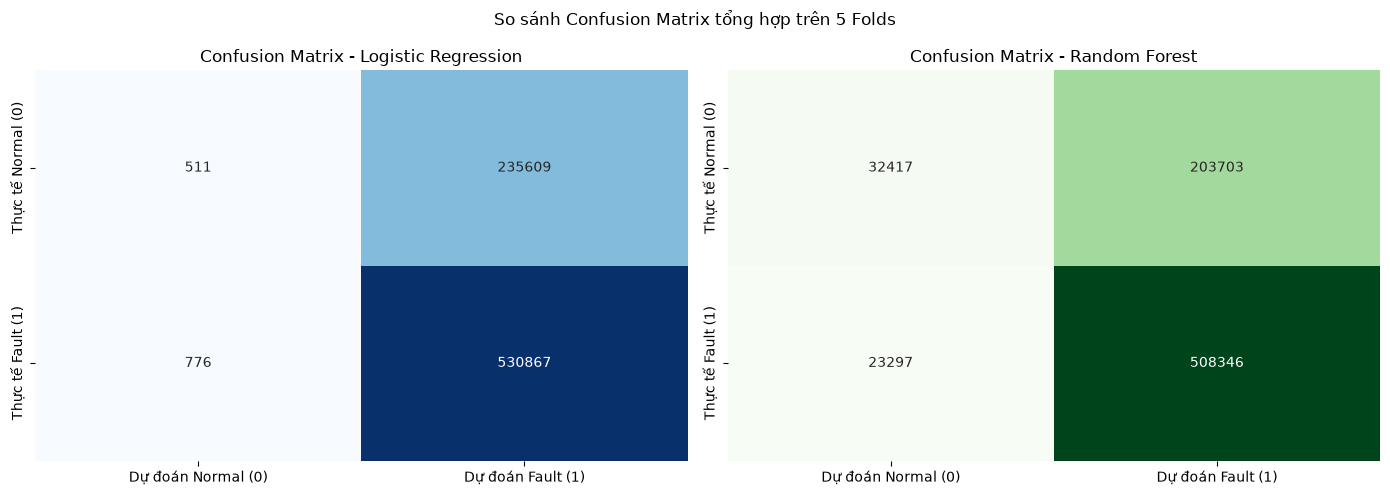

=== KẾT QUẢ KIỂM ĐỊNH THỐNG KÊ SO SÁNH 2 MÔ HÌNH ===


,Metric,Chênh lệch Mean (RF - LR),Paired t-test (t-stat),Paired t-test (p-value),Wilcoxon (p-value)
0,Precision,0.023750,2.788305,0.049397,0.0625
1,Recall,-0.042681,-4.203423,0.013658,0.0625
2,F1-score,0.000354,0.068584,0.948613,1.0000
3,Accuracy,0.013258,1.356854,0.246348,0.4375


In [4]:
# 1. Vẽ Confusion Matrix tổng hợp sau 5 Folds
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm_lr_total, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Dự đoán Normal (0)', 'Dự đoán Fault (1)'],
            yticklabels=['Thực tế Normal (0)', 'Thực tế Fault (1)'])
axes[0].set_title('Confusion Matrix - Logistic Regression')

sns.heatmap(cm_rf_total, annot=True, fmt='d', cmap='Greens', cbar=False, ax=axes[1],
            xticklabels=['Dự đoán Normal (0)', 'Dự đoán Fault (1)'],
            yticklabels=['Thực tế Normal (0)', 'Thực tế Fault (1)'])
axes[1].set_title('Confusion Matrix - Random Forest')

plt.suptitle("So sánh Confusion Matrix tổng hợp trên 5 Folds")
plt.tight_layout()
plt.show()

# 2. Thực hiện Statistical Test so sánh giữa Random Forest và Logistic Regression
stat_results = []
for metric in ['Precision', 'Recall', 'F1-score', 'Accuracy']:
    t_stat, p_ttest = stats.ttest_rel(df_rf_folds[metric], df_lr_folds[metric])
    try:
        w_stat, p_wilc = stats.wilcoxon(df_rf_folds[metric], df_lr_folds[metric], zero_method='zsplit')
    except ValueError:
        w_stat, p_wilc = np.nan, np.nan
        
    stat_results.append({
        'Metric': metric,
        'Chênh lệch Mean (RF - LR)': df_rf_folds[metric].mean() - df_lr_folds[metric].mean(),
        'Paired t-test (t-stat)': t_stat,
        'Paired t-test (p-value)': p_ttest,
        'Wilcoxon (p-value)': p_wilc
    })

df_stat_test = pd.DataFrame(stat_results)
print("=== KẾT QUẢ KIỂM ĐỊNH THỐNG KÊ SO SÁNH 2 MÔ HÌNH ===")
display(df_stat_test.round(6))

=== BẢNG PHÂN TÍCH LỖI (ERROR ANALYSIS) THEO TỪNG CHUYẾN BAY ===


,source_file,Label,Tong_Mau,Sai_LR,Ty_le_sai_LR,Sai_RF,Ty_le_sai_RF
0,FAULT_M1_10.mat,1,47019,3,0.01,3179,6.76
1,FAULT_M1_5.mat,1,64276,0,0.00,3911,6.08
2,FAULT_M2_10.mat,1,53865,0,0.00,668,1.24
3,FAULT_M2_5.mat,1,39209,0,0.00,638,1.63
4,FAULT_M3_10.mat,1,39244,0,0.00,2169,5.53
5,FAULT_M3_5.mat,1,63171,375,0.59,5599,8.86
6,FAULT_M4_10.mat,1,36213,105,0.29,822,2.27
7,FAULT_M4_5.mat,1,27601,21,0.08,729,2.64
8,FAULT_M5_10.mat,1,43491,93,0.21,1494,3.44
9,FAULT_M5_5.mat,1,32132,0,0.00,523,1.63


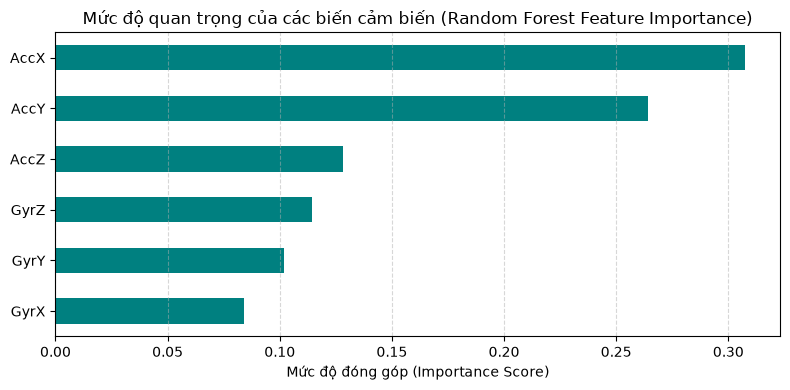

Số liệu Feature Importance:


AccX    0.3076
AccY    0.2642
AccZ    0.1280
GyrZ    0.1143
GyrY    0.1019
GyrX    0.0840
dtype: float64

In [5]:
# 1. Gộp kết quả dự đoán vào bảng để phân tích lỗi theo từng file
df_eval = df_uav.iloc[all_test_indices].copy()
df_eval['Pred_LR'] = all_preds_lr
df_eval['Pred_RF'] = all_preds_rf
df_eval['Error_LR'] = (df_eval['Label'] != df_eval['Pred_LR']).astype(int)
df_eval['Error_RF'] = (df_eval['Label'] != df_eval['Pred_RF']).astype(int)

error_by_file = df_eval.groupby(['source_file', 'Label']).agg(
    Tong_Mau=('Label', 'count'),
    Sai_LR=('Error_LR', 'sum'),
    Ty_le_sai_LR=('Error_LR', lambda x: round(x.mean() * 100, 2)),
    Sai_RF=('Error_RF', 'sum'),
    Ty_le_sai_RF=('Error_RF', lambda x: round(x.mean() * 100, 2))
).reset_index()

print("=== BẢNG PHÂN TÍCH LỖI (ERROR ANALYSIS) THEO TỪNG CHUYẾN BAY ===")
display(error_by_file)

# 2. Vẽ biểu đồ Feature Importance của Random Forest
plt.figure(figsize=(8, 4))
importances = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=True)
importances.plot(kind='barh', color='teal')
plt.title('Mức độ quan trọng của các biến cảm biến (Random Forest Feature Importance)')
plt.xlabel('Mức độ đóng góp (Importance Score)')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("Số liệu Feature Importance:")
display(importances.sort_values(ascending=False).round(4))